# Solving Durable model with price dispersion in infinite horizon

Compare steady-state aggregates and sequence-space Jacobians w.r.t. `Rfree` and `labor` across
price-dispersion magnitudes matching `Figures_Durable.ipynb` panel (c):

- $\sigma_p \in \{0.05, 0.1, 0.15\}$ (`PriceShkCount=5`)
- EV taste and search shut off (`sigma_eps=0`, `SearchCost=0`)

Saves results to `Output/DurableModel_Price_Inf_SS.pkl`,
`Output/DurableModel_Price_Inf_Jacobians_Rfree.pkl`, and
`Output/DurableModel_Price_Inf_Jacobians_labor.pkl`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
import pickle
from pathlib import Path

import pandas as pd
from IPython.display import display

start_time = time.time()

from DurableModel_Fast import DurableConsumer

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = Path("../Output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Line styles matching Figures_Durable.ipynb smoothing-shift overlays
LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]

SS_KEYS = ["C", "D", "DEX", "TEX", "A", "ADJ"]
JAC_KEYS = ["C", "DEX", "TEX", "D", "A", "ADJ"]


In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.10,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=10, #5.0,
    nNrmCount=200,
    mNrmMax=16.0, #8.0,
    mNrmCount=200,
    xNrmMax=26, #13.0,
    xNrmCount=100,
    aNrmMax=16.0, #8.0,
    aNrmCount=200,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-8,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=500,  # iteration cap for cycles=0 (matches background max_cycles)
    min_cycles=200,  # minimum IH iterations before tol can stop
    distance_metric="mse",
    verbose=False,
)


In [3]:
# Price-dispersion channel only (hard max keep--adjust), matching Figures_Durable panel (c)
base_price = copy.deepcopy(durable_defaults)
base_price["sigma_eps"] = 0.0
base_price["SearchCost"] = 0.0
base_price["PriceShkStd"] = 0.0
base_price["PriceShkCount"] = 1
base_price["TranMatrixmCount"] = 250
base_price["diagnostics"] = False

# Same grid as Figures_Durable.ipynb smoothing shifts
p_vals = [0.05, 0.1, 0.15]
param_labels = [rf"$\sigma_{{p}} = {ps}$" for ps in p_vals]

T = 50


In [4]:
results = []
for ps, lab in zip(p_vals, param_labels):
    print(f"Solving / SS / Jacobian: PriceShkStd={ps}...")
    params = copy.deepcopy(base_price)
    params["PriceShkStd"] = ps
    params["PriceShkCount"] = 5
    model = DurableConsumer(**params)
    model.compute_steady_state()
    print(
        f"  converged in {model.completed_cycles} cycles, "
        f"{model.distance_metric} distance = {model.distance:.3e}"
    )# Kinks already on solution[0] from solve; fill Judd Euler residuals.
    model.compute_euler_errors()
    sol0 = model.solution[0]
    kink_euler = {
        "Specification": lab,
        "Decr. seg.": sol0.keep_decreasing_segments,
        "Keep share": sol0.keep_share_decreasing,
        "FUES rem.": sol0.adj_kinks_removed,
        "Adj share": sol0.adj_share_removed,
        "EE_c keep mean": sol0.ee_c_keep_mean,
        "EE_c keep p95": sol0.ee_c_keep_p95,
        "EE_c adj mean": sol0.ee_c_adj_mean,
        "EE_c adj p95": sol0.ee_c_adj_p95,
        "EE_d adj mean": sol0.ee_d_adj_mean,
        "EE_d adj p95": sol0.ee_d_adj_p95,
        "n keep": getattr(sol0, "ee_c_keep_n", None),
        "n adj": getattr(sol0, "ee_d_adj_n", None),
    }
    J_C_Rfree, J_DEX_Rfree, J_TEX_Rfree, J_D_Rfree, J_A_Rfree, J_ADJ_Rfree = model.calc_jacobian("Rfree", T)
    J_C_labor, J_DEX_labor, J_TEX_labor, J_D_labor, J_A_labor, J_ADJ_labor = model.calc_jacobian("labor", T)
    results.append(
        dict(
            channel="price",
            param_name="PriceShkStd",
            param_col=r"$\sigma_p$",
            param=ps,
            label=lab,
            kink_euler=kink_euler,
            ss=dict(
                C=float(model.C_ss),
                D=float(model.D_ss),
                DEX=float(model.DEX_ss),
                TEX=float(model.TEX_ss),
                A=float(model.A_ss),
                ADJ=float(model.ADJ_ss),
            ),
            jacobians_Rfree=dict(C=J_C_Rfree, DEX=J_DEX_Rfree, TEX=J_TEX_Rfree, D=J_D_Rfree, A=J_A_Rfree, ADJ=J_ADJ_Rfree),
            jacobians_labor=dict(C=J_C_labor, DEX=J_DEX_labor, TEX=J_TEX_labor, D=J_D_labor, A=J_A_labor, ADJ=J_ADJ_labor),
        )
    )
print("Finished all price-dispersion variants.")


Solving / SS / Jacobian: PriceShkStd=0.05...


C:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


C:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


C:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


C:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\scipy\sparse\_index.py:151: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


...

Solving / SS / Jacobian: PriceShkStd=0.1...


  converged in 200 cycles, mse distance = 5.013e-25


Solving / SS / Jacobian: PriceShkStd=0.15...


  converged in 203 cycles, mse distance = 4.786e-09


Finished all price-dispersion variants.


In [5]:
# Steady-state comparison table
ss_rows = []
for r in results:
    row = {r["param_col"]: r["param"]}
    row.update(r["ss"])
    ss_rows.append(row)

ss_table = pd.DataFrame(ss_rows).set_index(results[0]["param_col"])
ss_table = ss_table[SS_KEYS]
print("Steady-state aggregates by price dispersion")
display(ss_table.style.format("{:.6f}"))


Steady-state aggregates by price dispersion


,C,D,DEX,TEX,A,ADJ
$\sigma_p$,,,,,,
0.050000,0.808562,4.066806,0.203340,1.011903,1.296349,0.123876
0.100000,0.809874,5.079330,0.266042,1.075916,0.760631,0.200000
0.150000,0.728202,5.471434,0.471435,1.199637,1.059023,0.200000


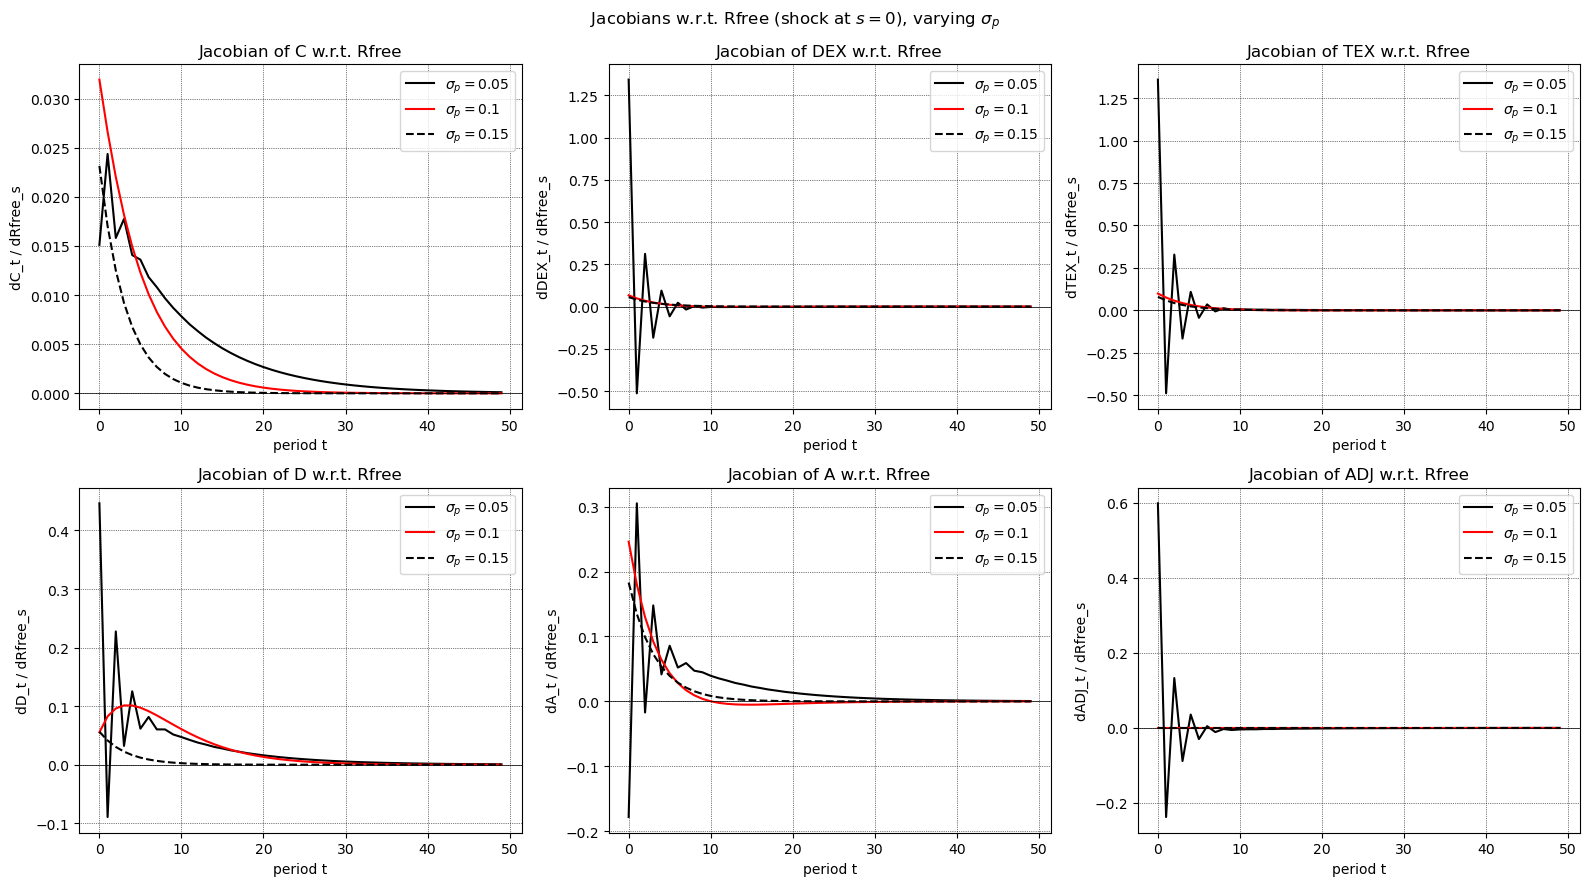

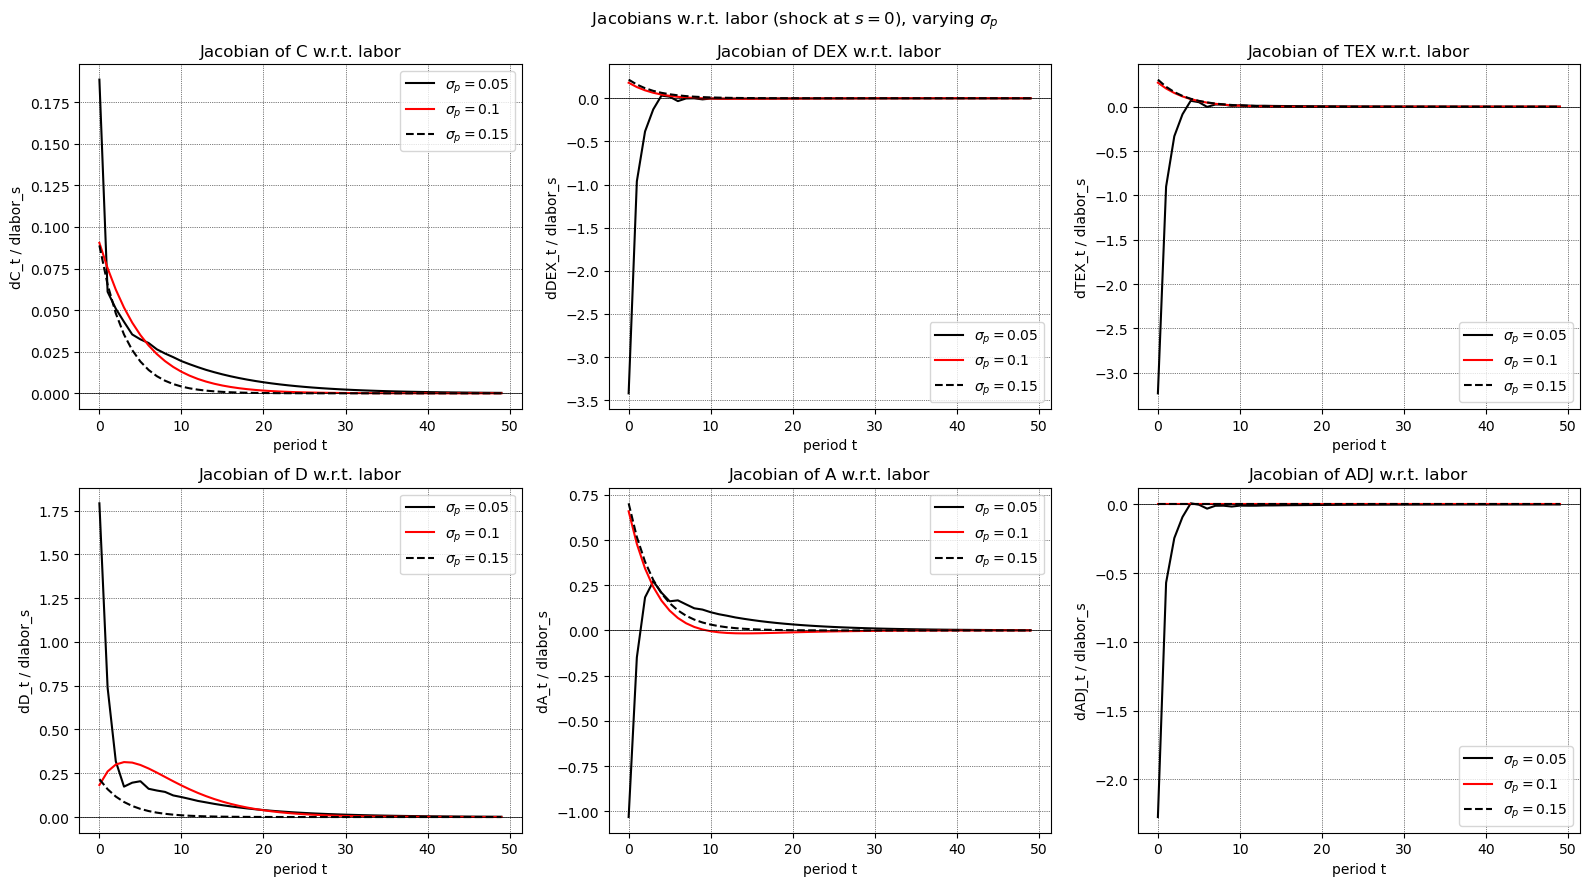

In [6]:
# Overlay Jacobians across parameter values (IRF to period-0 shock)
# Linestyles follow Figures_Durable.ipynb smoothing overlays.
shock_s = 0  # column of Jacobian = date of shock

# --- Rfree ---
SUPTITLE_R = r'Jacobians w.r.t. Rfree (shock at $s=0$), varying $\sigma_{p}$'
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_Rfree"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. Rfree")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dRfree_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(SUPTITLE_R)
fig.tight_layout()
plt.show()

# --- labor ---
SUPTITLE_L = r'Jacobians w.r.t. labor (shock at $s=0$), varying $\sigma_{p}$'
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_labor"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. labor")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dlabor_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(SUPTITLE_L)
fig.tight_layout()
plt.show()


In [7]:
# Save steady states and Jacobians as separate pickles
ss_payload = {
    "channel": results[0]["channel"],
    "param_name": results[0]["param_name"],
    "param_col": results[0]["param_col"],
    "param_values": [r["param"] for r in results],
    "labels": [r["label"] for r in results],
    "steady_states": {r["param"]: r["ss"] for r in results},
    "kink_euler": {r["param"]: r["kink_euler"] for r in results},
    "kink_euler_t": 0,
    "ss_table": ss_table,
}

jac_meta = dict(
    channel=results[0]["channel"],
    param_name=results[0]["param_name"],
    param_col=results[0]["param_col"],
    param_values=[r["param"] for r in results],
    labels=[r["label"] for r in results],
    T=T,
    shock_s_plotted=0,
)

jac_payload_Rfree = {
    **jac_meta,
    "shk_param": "Rfree",
    "jacobians": {r["param"]: r["jacobians_Rfree"] for r in results},
}
jac_payload_labor = {
    **jac_meta,
    "shk_param": "labor",
    "jacobians": {r["param"]: r["jacobians_labor"] for r in results},
}

ss_path = OUT_DIR / "DurableModel_Price_Inf_SS.pkl"
jac_path_Rfree = OUT_DIR / "DurableModel_Price_Inf_Jacobians_Rfree.pkl"
jac_path_labor = OUT_DIR / "DurableModel_Price_Inf_Jacobians_labor.pkl"
with open(ss_path, "wb") as f:
    pickle.dump(ss_payload, f)
with open(jac_path_Rfree, "wb") as f:
    pickle.dump(jac_payload_Rfree, f)
with open(jac_path_labor, "wb") as f:
    pickle.dump(jac_payload_labor, f)

elapsed = time.time() - start_time
print(f"Saved {ss_path.resolve()}")
print(f"Saved {jac_path_Rfree.resolve()}")
print(f"Saved {jac_path_labor.resolve()}")
print("Done in", str(datetime.timedelta(seconds=elapsed)))


Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Price_Inf_SS.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Price_Inf_Jacobians_Rfree.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Price_Inf_Jacobians_labor.pkl
Done in 0:13:10.379639


In [8]:
model.solution[0].xAdj_pre_list

[array([8.46476372, 8.89963277]),
 array([ 3.73270161,  3.93397716,  4.13805084,  4.35276184,  4.57132094,
         4.79840759,  5.03335179,  5.27834884,  5.52975745,  5.79158975,
         6.06071501,  6.34000571,  6.62809182,  6.92757288,  7.23797881,
         7.55977927,  7.89316925,  8.23961982,  8.60828392,  9.02123482,
         9.50604318, 10.07064072, 10.70263258, 11.38518533, 12.10368606,
        12.84924725, 13.6190593 , 14.41582734, 15.23687948, 16.08361165,
        16.95835549, 17.85675094, 18.78447676, 19.74201589, 20.72385561,
        21.73417555, 22.77480661, 23.84681957]),
 array([ 1.96717258,  2.05169556,  2.2008966 ,  2.40190719,  2.54403223,
         2.69268109,  2.8483394 ,  3.01111253,  3.18260226,  3.36353861,
         3.55594988,  3.76208316,  3.98179501,  4.21142997,  4.44989439,
         4.69758265,  4.95441713,  5.22061781,  5.4966043 ,  5.78233218,
         6.07787352,  6.38353012,  6.69954909,  7.02585316,  7.36331192,
         7.71140074,  8.07123599,  8.4440